In [1]:
import subprocess
import sys

COLAB = "google.colab" in sys.modules


def _install(package):
    if COLAB:
        ans = input(f"Install { package }? [y/n]:")
        if ans.lower() in ["y", "yes"]:
            subprocess.check_call(
                [sys.executable, "-m", "pip", "install", "--quiet", package]
            )
            print(f"{ package } installed!")


def _colab_install_missing_deps(deps):
    import importlib

    for dep in deps:
        if importlib.util.find_spec(dep) is None:
            if dep == "iris":
                dep = "scitools-iris"
            _install(dep)


deps = ["ioos_qc"]
_colab_install_missing_deps(deps)

#   IOOS QARTOD on Glider Data
Created: 2026-10-02

Updated: 2026-10-22

During the 2026 Google Summer of Code, a project was [proposed to evaluate](https://github.com/ioos/gsoc/issues/102) the tests present in the [QARTOD glider manual](https://cdn.ioos.noaa.gov/media/2017/12/Manual-for-QC-of-Glider-Data_05_09_16.pdf), which had recently turned 10 years old. The final project was called ["Filling the gaps within the IOOS quality control schema for ocean glider data"](https://summerofcode.withgoogle.com/programs/2026/projects/bJGGUbsA) which led to a [series of investigative notebooks](https://github.com/Klankers/mau_gsoc_qartod) that did the following for tests listed within the manual:
1. Looked at the manual's description and assessed if it made sense.
2. Looked within the [IOOS QC codebase](https://github.com/ioos/ioos_qc/tree/main/ioos_qc) and assessed if it was authentic and genuine to the manual. If not, look at where the differences were and what they would do in practice.
3. Given the unknown recent activity of the manual's original authors, make additions or changes to the QARTOD toolbox to more comprehensively perform what is described in the manual.

This general procedure was done for the following tests:
1. Timing/Gap Test
2. Syntax Test
3. Location Test
4. Gross Range Test
5. Pressure Test
6. Climatology Test
14. (As ordered in the manual) Density Inversion Test

This notebook seeks to demonstrate how the tests can be used on ocean glider datasets. Unfortunately, the following tests were not assessed:

7. Spike Test
8. Rate of Change Test
9. Flat Line TEst
10. Multi-Variate Test
11. Attenuated Signal Test
12. Previous Profile Test
13. TS Curve/Space Test

As such, these tests will not be listed in this notebook unless updated at a later date.

Experimentation during the 2026 Google Summer of Code was commonly done on gliders using the [OG1 format](https://oceangliderscommunity.github.io/OG-format-user-manual/OG_Format.html). Plots, statistics, and any other outputs from this notebook are therefore entirely intended for educational purposes and are not intended to critically reflect on the dataset being used. Note that the results and settings present in this notebook may differ from those found at other institutions.

Data for this notebook is sourced from the Voice of the Ocean Foundation's ALSEAMAR *SeaExplorer* fleet, operating in the [Skagerrak](https://en.wikipedia.org/wiki/Skagerrak) between 2021 and 2026. This region is characterized by the interaction between deep, salty water from the [North Sea](https://en.wikipedia.org/wiki/North_Sea) interacting with fresh, relatively warm outflow from the [Baltic Sea](https://en.wikipedia.org/wiki/Baltic_Sea), passing through the [Danish Straits](https://en.wikipedia.org/wiki/Danish_Straits) and [Kattegat](https://en.wikipedia.org/wiki/Kattegat). This gives a temperature profile that is normally expected (warmest water at the surface), though the salinity profile is opposite of that typical in ocean gyres or open ocean (here, fresh water is on top).

The dataset to be used is [mission #109 of SeaExplorer number 044](https://erddap.observations.voiceoftheocean.org/erddap/files/OG_complete_SEA044_M109/), operating for 20 days in September 2025.

## Load the data
Starting with imports and loading the dataset.

In [2]:
#   For loading data
import pooch
import xarray as xr

#   Contains all of our tests
from ioos_qc import qartod

#   20261022: Extracting all the plotting code.
#   The plotting helpers live next to this notebook. The file name isn't a valid module name, so load it by path.
import importlib.util
spec = importlib.util.spec_from_file_location("plotting_helpers", "2026-10-22-QARTOD-help-plot.py")
plotting_helpers = importlib.util.module_from_spec(spec)
spec.loader.exec_module(plotting_helpers)

url = "https://erddap.observations.voiceoftheocean.org/erddap/files/OG_complete_SEA044_M109/"
fname = "sea044_20250905T0639_delayed.nc"
filehash = "0bce25b78fc40bd7888a76909faa60b4f6490afd44b68a7f1f56c9d7611020ab"
#   VOTO's file hashes are not public as of September 2026. I've computed it using Python's 'hashlib'

download = pooch.retrieve(
    url=f"{url}{fname}",
    known_hash=f"sha256:{filehash}"
)
ds = xr.open_dataset(download)
ds

<xarray.Dataset> Size: 245MB
Dimensions:                             (N_MEASUREMENTS: 1699082)
Coordinates:
  * N_MEASUREMENTS                      (N_MEASUREMENTS) int64 14MB 0 ... 169...
    LATITUDE                            (N_MEASUREMENTS) float64 14MB ...
    LONGITUDE                           (N_MEASUREMENTS) float64 14MB ...
    TIME                                (N_MEASUREMENTS) datetime64[ns] 14MB ...
    DEPTH                               (N_MEASUREMENTS) float64 14MB ...
Data variables: (12/31)
    AD2CP_HEADING                       (N_MEASUREMENTS) float32 7MB ...
    AD2CP_PITCH                         (N_MEASUREMENTS) float32 7MB ...
    AD2CP_ROLL                          (N_MEASUREMENTS) float32 7MB ...
    BBP700                              (N_MEASUREMENTS) float32 7MB ...
    CHLA                                (N_MEASUREMENTS) float32 7MB ...
    DIVE_NUMBER                         (N_MEASUREMENTS) int64 14MB ...
    ...                                  ...
    SENSOR_CURRENT_PROFILERS_105527     float64 8B ...
    SENSOR_DISSOLVED_GAS_SENSORS_0095   float64 8B ...
    SENSOR_FLUOROMETERS_235280          float64 8B ...
    SENSOR_MICROSTRUCTURE_SENSORS_0496  float64 8B ...
    PROFILE_NUMBER                      (N_MEASUREMENTS) int64 14MB ...
    PROFILE_DIRECTION                   (N_MEASUREMENTS) int64 14MB ...
Attributes: (12/67)
    Conventions:                                CF-1.10, OG-1.0, Unidata Data...
    acknowledgement:                            This study used data collecte...
    agency:                                     Voice of the Ocean
    agency_role:                                contact point
    agency_role_vocabulary:                     http://vocab.nerc.ac.uk/colle...
    cdm_data_type:                              Trajectory
    ...                                         ...
    start_date:                                 20250905T0639
    basin:                                      Skagerrak
    total_dives:                                616
    dataset_id:                                 delayed_SEA044_M109
    data_url:                                   https://erddap.observations.v...
    variables:                                  ['AD2CP_HEADING', 'AD2CP_PITC...

## A note on flags
A quick disclaimer that all flags in this notebook adhere to a set defined in the QARTOD data flags manual (not just the glider manual) and [UNESCO 2013](https://www.ioccp.org/images/D4standards/IOC-OceanDataStandards54-3-2013.pdf). There are 5 flags described:

| Flag | Meaning | Definition |
|------|---------|------------|
| 1 | GOOD | Passed documented required QC tests |
| 2 | UNKNOWN (not evaluated) | Used for data when no QC test performed or the information on quality is not available |
| 3 | SUSPECT | Failed non‐critical documented metric or subjective test(s) |
| 4 | FAIL | Failed critical documented QC test(s) or as assigned by the data provider |
| 9 | MISSING | Used as place holder when data are missing |

Note that these flags differ from those used at other institutions (Argo, for example, has flag=0 for UNKNOWN).

In [3]:
from ioos_qc.qartod import QartodFlags  #   These are stored in a Class in qartod
print(dir(QartodFlags))
print(f"Unknown flag = {QartodFlags.UNKNOWN}")

#   Each flag is tied to a label and a color in the plotting helpers.
flag_style = plotting_helpers.flag_style

['FAIL', 'GOOD', 'MISSING', 'SUSPECT', 'UNKNOWN', '__class__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__firstlineno__', '__format__', '__ge__', '__getattribute__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__sizeof__', '__static_attributes__', '__str__', '__subclasshook__', '__weakref__']
Unknown flag = 2


QARTOD commonly flags by cascading flags onto one another by severity. I.e., everything is untested (2) until it is passed into a test, where it is considered good. If *anything* goes wrong, this good flag is overwritten by a missing flag (9, typically handled with a numpy mask), a suspect flag (3), or straight up failing (4).

In [4]:
order = plotting_helpers.order
print(order)

[2, 1, 9, 3, 4]


## Preliminary data check
Let's take a quick look at the data now that we've got it loaded and some helpers up and running, while also deriving some parameters we'll use later.
* PSAL - practical salinity from conductivity.
* SA - absolute salinity from practical salinity.
* CT - conservative temperature, coming from absolute salinity and the original temperature
* SIGMA0 - or $\sigma_\theta$, typically described as the potential density referenced to the surface.

We can get these with `gsw`, which uses the TEOS-10 algorithms.

In [5]:
import gsw
import numpy as np
ds["PSAL"] = gsw.SP_from_C(ds.CNDC, ds.TEMP, ds.PRES)
ds["SA"] = gsw.SA_from_SP(ds.PSAL, ds.PRES, ds.LONGITUDE, ds.LATITUDE)
ds["CT"] = gsw.CT_from_t(ds.SA, ds.TEMP, ds.PRES)
ds["SIGMA0"] = gsw.sigma0(ds.SA, ds.CT)

time = ds.TIME.values
pres = ds.PRES.values
temp = ds.TEMP.values
psal = ds.PSAL.values
sigma0 = ds.SIGMA0.values
profile = ds.PROFILE_NUMBER.values
direction = ds.PROFILE_DIRECTION.values  # 1 = descending, -1 = ascending

print(f"{time.size} measurements in {np.unique(profile).size} profiles")
print(f"{np.datetime_as_string(time[0], unit='m')} to {np.datetime_as_string(time[-1], unit='m')}")

1699082 measurements in 1232 profiles
2025-09-05T06:39 to 2025-09-25T09:24


And of course, we should look at the data from a geospatial perspective. In the `location_on_land` test, this is done using the package `roaring_landmask` for high-resolution coastlines.

In [6]:
extent = (8.8, 11.6, 57.4, 59.2)  # lon_min, lon_max, lat_min, lat_max

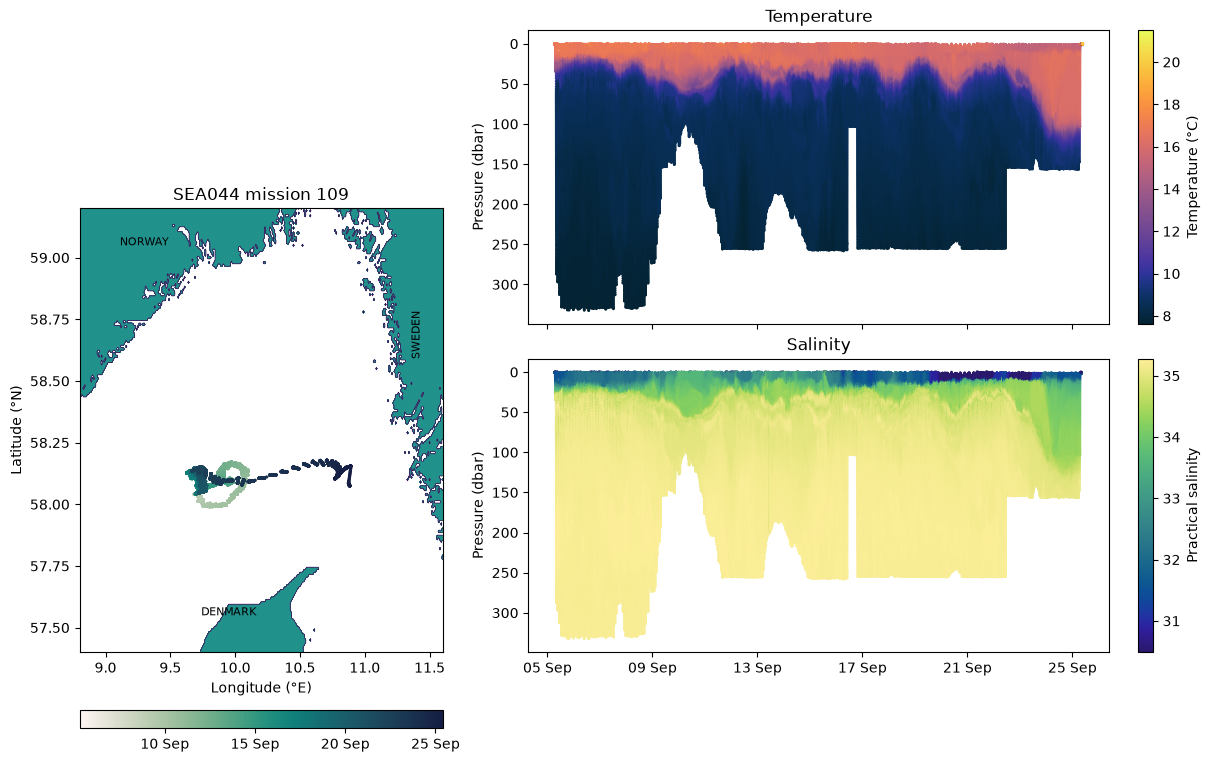

In [7]:
fig, axs = plotting_helpers.overview_figure(ds.LONGITUDE.values, ds.LATITUDE.values, time, pres, temp, psal, extent)

This shows that the glider started up and did a loop, before transitioning closer to Sweden (most likely for recovery).

## Timing/Gap Test
This test was not present in the toolbox prior to GSoC, mostly because there was not a clear consensus in the community of exactly what it should look like or do. Gliders do not provide a data stream as they cannot communicate while underwater. Instead, they bundle the most recent data and communicate that over satellite.

With this context in mind, it made sense to break this test up into 3 use cases:
1. Impossible dates. I.e., something that will check the `TIME` coordinate or variable and ensure that it adheres to a "reasonable" round, like how the manual describes it.
  * Data is either present or in the past.
  * Month, day, hour, minute are all possible (Numpy datetime64 does not tolerate impossible values)
  * Include user-specified tolerances. If the glider was deployed last week, you wouldn't expect a datetime from 4 years ago.
2. Data reception. The manual describes a `TIM_INC` increment to flag data by if they're older than that. This is potentially more handy for data centers, as they'll be *expecting* data at certain intervals. For example, you could have a glider that is returning totally reasonable datetimes, they're just not coming in as recent as you've specified.
3. Time gaps. This is perhaps the most obvious one that can't really be assessed in real-time, but if the glider doesn't record a data point within an expected period, that gap should be flagged. This is a helpful test for finding inconsistencies in glider reporting - helpful for engineering troubleshooting or when working with time-series analyses that are sensitive to uneven sampling rates.

### Impossible Dates
This test runs with an optional argument with a `fail_span`, used to designate a user-defined window of times where data can be potentially bad.

To demonstrate this, let's inject some fake data and show the `fail_span` in action.

In [8]:
#   This is a quick helper function that we can pass any flags into and get flag information out of
def flag_counts(flags, name=""):
    flags = np.ma.getdata(flags)
    parts = [
        f"{flag_style[f][0]}={np.count_nonzero(flags == f):,}" for f in order if np.any(flags == f)
    ]
    print(f"{name:<28s}" + ", ".join(parts))

In [9]:
time_bad = time.copy()
injected = {
    200000: np.datetime64("2031-02-14T12:00:00"),  #    in the future
    600000: np.datetime64("1970-01-01T00:00:00"),  #    Unix epoch
    900000: np.datetime64("2025-08-15T00:00:00"),  #    before the deployment
    1200000: np.datetime64("NaT", "ns"),  # missing
}
for i, t in injected.items():
    time_bad[i] = t

deployed = ds.DEPLOYMENT_TIME.values
window = (deployed, deployed + np.timedelta64(30, "D")) #   Let's say we add 30 days or so from the beginning of the deployment.

flags_date = qartod.impossible_date_test(time_bad)
flags_date_window = qartod.impossible_date_test(time_bad, fail_span=window)

flag_counts(flags_date, "No window:")
flag_counts(flags_date_window, "Deployment window:")

No window:                  GOOD=1,699,080, MISSING=1, FAIL=1
Deployment window:          GOOD=1,699,078, MISSING=1, FAIL=3


As you can see above, only one data point fails without using the `fail_span`, since the default `impossible_date_test` is just looking for values that can't logically happen (accounting for time travelers). The only point that fails is the value from 2031, whereas adding the window further constrains what is acceptable.

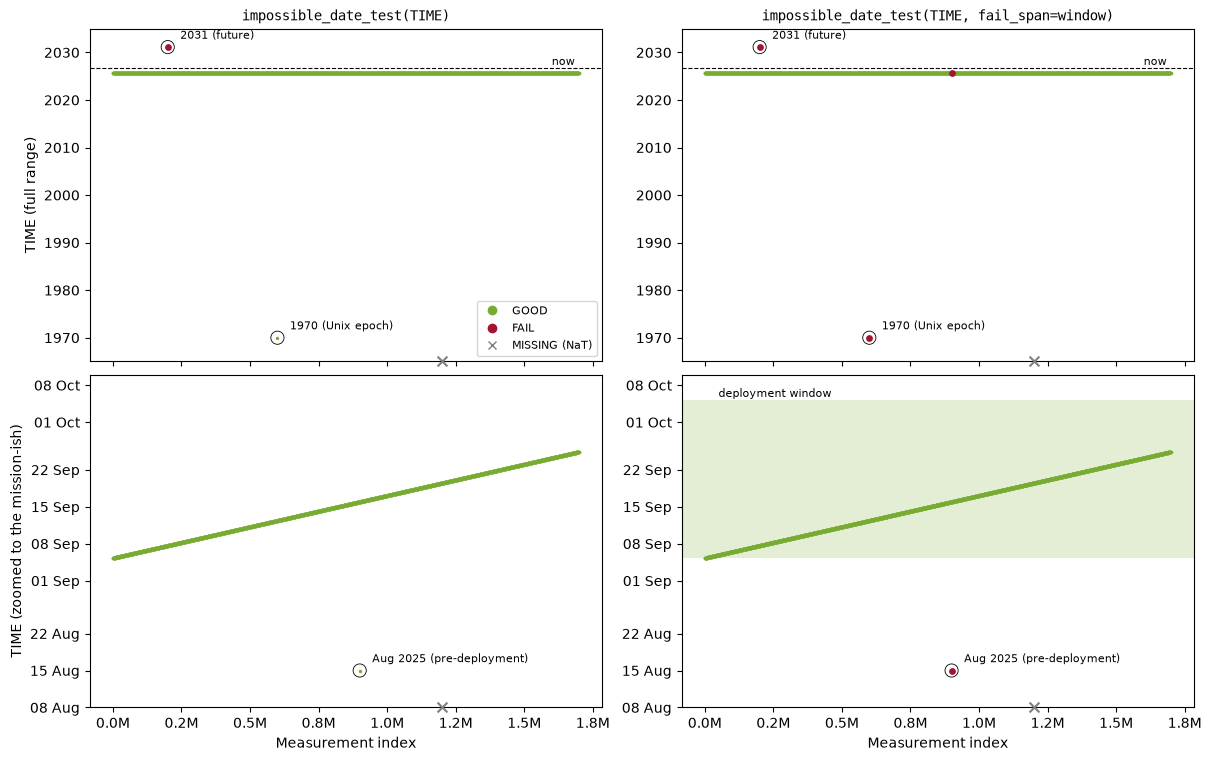

In [10]:
labels = {200000: "2031 (future)", 600000: "1970 (Unix epoch)", 900000: "Aug 2025 (pre-deployment)"}
fig, axs = plotting_helpers.impossible_date_figure(time_bad, flags_date, flags_date_window, window, injected, labels)

### Data Reception
The data reception test originated from a potential use for data centers. Let's pretend the check happens 10 days into the mission (`from_time`):
* data more than 48 h older than `from_time` is stale, so **FAIL**,
* data within 48 h of `from_time` is **GOOD**,
* data *newer* than `from_time` is not judged by this test and passes through as **GOOD**.

With the default `from_time` (now), every point in a 2025 dataset is stale. If you're reading this and running this notebook, your data will all be stale on the original dataset as well.

The test is not meant for archived data like this! It's a kind of a gap test intended for use by a listener and pairs best with NRT data.

In [11]:
check_time = time[0] + np.timedelta64(10, "D")  #   Need to assign based on time[0] plus some offset
max_age_hours = 48

flags_rx = qartod.data_reception_test(time, fail_span=max_age_hours, from_time=check_time)
flag_counts(flags_rx, f"from_time = {np.datetime_as_string(check_time, unit='h')}:")
flag_counts(qartod.data_reception_test(time, fail_span=max_age_hours), "from_time = now:")

from_time = 2025-09-15T06:  GOOD=1,023,164, FAIL=675,918
from_time = now:            FAIL=1,699,082


So with the span defined, we can see that the data is more or less split, which we're expecting given the mission is longer than what we speicified at 10 days duration.

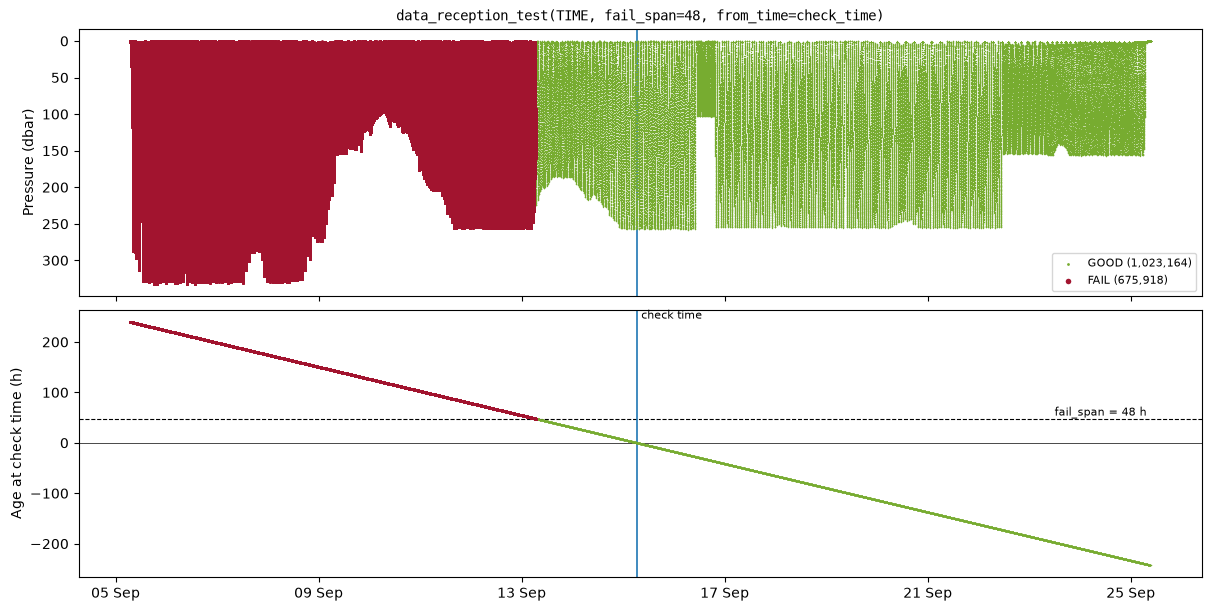

In [12]:
fig, axs = plotting_helpers.data_reception_figure(time, pres, flags_rx, check_time, max_age_hours)

### Time Gaps
Next comes the first thing that a user is probably thinking of when it comes to a time/gap test - where is my data not spaced appropriately? Where are the holes in my data?

This is also where the duplicate timestamps noticed during GSoC'26 show up: thousands of steps are exactly zero. They are not gaps, so `time_gap_test` doesn't flag them, but they are worth knowing about and might warrant further exploration.

In [13]:
dt_seconds = np.diff(time) / np.timedelta64(1, "s")
print(f"Median step: {np.median(dt_seconds)} s, longest: {dt_seconds.max()} s, zero-length (duplicates): {np.count_nonzero(dt_seconds == 0)}")

Median step: 1.0 s, longest: 125.0 s, zero-length (duplicates): 4500


In the data loaded here, most data points are spaced at about a second apart. However, there are some real gaps that can arise.

In [14]:
flag_counts(qartod.time_gap_test(time), "fail_span = 2 h:")
flag_counts(qartod.time_gap_test(time, fail_span=1 / 60), "fail_span = 1 min:")

fail_span = 2 h:            GOOD=1,699,082
fail_span = 1 min:          GOOD=1,699,072, FAIL=10


As you can see above, the default limit of two hours doesn't find anything - which says more about our data than the test! There are only a few points that are a minute or longer. The point that *follwos* the gap is what is flagged.

To see a real gap we can simulate a data dropout by deleting six hours of measurements from the middle of the mission, as might happen if a data file was lost. Then we run the test with its default 2 h `fail_span`.

In [15]:
gap_start = np.datetime64("2025-09-15T06:00")
gap_end = gap_start + np.timedelta64(6, "h")
keep = (time < gap_start) | (time >= gap_end)

time_gappy = time[keep]
pres_gappy = pres[keep]
flags_gap = qartod.time_gap_test(time_gappy, fail_span=2)
flag_counts(flags_gap, "Simulated dropout:")
print("Flagged point:", np.datetime_as_string(time_gappy[np.ma.getdata(flags_gap) == QartodFlags.FAIL][0], unit="s"))

Simulated dropout:          GOOD=1,677,961, FAIL=1
Flagged point: 2025-09-15T12:00:00


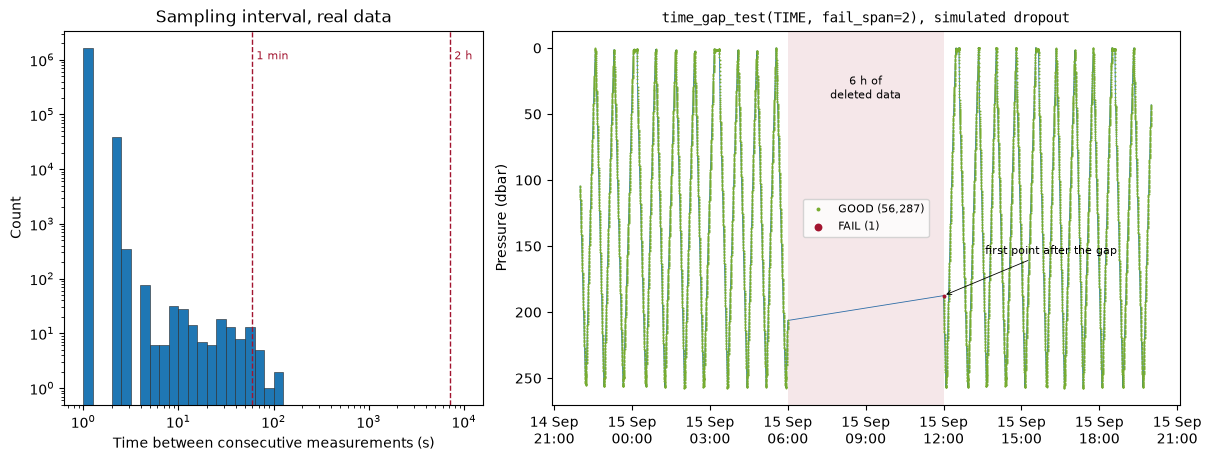

In [16]:
fig, axs = plotting_helpers.time_gap_figure(dt_seconds, time_gappy, pres_gappy, flags_gap, gap_start, gap_end)

## Syntax Test
This is a test that is described in the manual to a certain extent, but was also very polarizing when discussing with indiviual glider groups. How do you test something that differs wildly from glider model to glider model, with some manufacturers not having "raw" data available at all? Possibly a relic of the zeitgeist prior to the major glider manufacturers of the 2020s, the syntax test has been implemented here to be more generic for some of the raw messages that a glider can transmit. These messages are hard to get a hand of, but the basic function can still be applied to real-world data even though our data is in OG1 format.

The syntax test works on the **raw messages** a glider sends, before they are parsed into numbers. Common among these is HEX or hexadecimal format, which can then be parsed into bytes.
> CF010502AF02470085010101169217199E9401AD85091F48979B004662240E - an example HEX string from Argo.

So there are multiple ways that the data could be parsed - it could be a HEX-encoded string like above, or a more conventional list of characters, perhaps with a delimiter (like glider NMEA strings).

Each message is checked for having the expected length, measured in one of three ways:
* `lentype="char"`: number of characters,
* `lentype="byte"`: number of bytes in a HEX-encoded string (two characters per byte),
* `delimiter=";"`: number of fields once the message is split on a delimiter.

Putting this into practice, let's rebuild some semicolon-delimited records with time, state, pressure, T, and C to test the `char` argument. Kinda like a fake NMEA. Then we can "damage" it, something that a cycle redundancy check would look for.
* Truncation - when data gets cut off
* Dropping a field - like if for whatever reason a sensor goes offline
* Stray char - when something isn't collapsed correctly in the raw data or some static noise is introduced through a bad config
* Records merged - very common on CTDs when writing to a physical disk too slowly, missing the newline

In [17]:
ix = 500000
n_meas = 40
sub = slice(ix, ix+n_meas)
records = []
for t, nav, p, tc, c in zip(
    time[sub],
    ds.NAV_RESOURCE.values[sub],
    pres[sub],
    temp[sub],
    ds.CNDC.values[sub],
    strict=True,
):
    records.append(
        f"{np.datetime_as_string(t, unit='ms')};"
        f"{nav:03.0f};{p:08.3f};{tc:07.4f};{c:07.4f}"
    )
good_len = len(records[0])
good_field = len(records[0].split(";"))
print(f"{len(records)} items: {records}")
print(f"Good length = {good_len} characters. Good field length = {good_field}")

40 items: ['2025-09-11T04:41:49.000;118;0200.145;08.0313;36.5509', '2025-09-11T04:41:50.000;118;0200.207;08.0303;36.5479', '2025-09-11T04:41:51.000;118;0200.258;08.0287;36.5464', '2025-09-11T04:41:52.000;118;0200.299;08.0273;36.5465', '2025-09-11T04:41:53.000;118;0200.321;08.0273;36.5486', '2025-09-11T04:41:54.000;118;0200.331;08.0254;36.5453', '2025-09-11T04:41:55.000;118;0200.331;08.0254;36.5457', '2025-09-11T04:41:56.000;118;0200.312;08.0239;36.5448', '2025-09-11T04:41:57.000;118;0200.274;08.0239;36.5457', '2025-09-11T04:41:58.000;118;0200.230;08.0233;36.5467', '2025-09-11T04:41:59.000;118;0200.176;08.0233;36.5461', '2025-09-11T04:42:00.000;118;0200.105;08.0240;36.5458', '2025-09-11T04:42:01.000;118;0200.024;08.0241;36.5453', '2025-09-11T04:42:02.000;118;0199.927;08.0235;36.5458', '2025-09-11T04:42:03.000;118;0199.826;08.0236;36.5459', '2025-09-11T04:42:04.000;118;0199.706;08.0238;36.5459', '2025-09-11T04:42:05.000;118;0199.579;08.0237;36.5461', '2025-09-11T04:42:06.000;118;0199.438

A good record is 52 characters long, with 5 fields.

In [18]:
print("And these are the damaged guys:")
print(f"Nothing wrong:      {records[0]}")
#   By index to transform the line
damage = {
    6: ("truncated", lambda r: r[:-3]),  # transmission cut off
    15: ("field dropped", lambda r: ";".join(r.split(";")[:3] + r.split(";")[4:])),
    24: ("stray character", lambda r: r[:30] + "#" + r[30:]),
    33: ("records merged", lambda r: r + records[34]),
}
for i, (what, fn) in damage.items():
    records[i] = fn(records[i])
    print(f"{i:>2d} {what:<16s} {records[i]}")
records = np.array(records)

And these are the damaged guys:
Nothing wrong:      2025-09-11T04:41:49.000;118;0200.145;08.0313;36.5509
 6 truncated        2025-09-11T04:41:55.000;118;0200.331;08.0254;36.5
15 field dropped    2025-09-11T04:42:04.000;118;0199.706;36.5459
24 stray character  2025-09-11T04:42:13.000;118;01#98.307;08.0246;36.5467
33 records merged   2025-09-11T04:42:22.000;118;0196.500;08.0314;36.55432025-09-11T04:42:23.000;118;0196.299;08.0352;36.5582


We can run this two ways: By **counting characters** or delimited **fields**.

In [19]:
flags_char = qartod.syntax_test(records, nchar=good_len, lentype="char")
flags_field = qartod.syntax_test(records, nchar=good_field, delimiter=";")
flag_counts(flags_char, "By characters:")
flag_counts(flags_field, "By fields:")

By characters:              GOOD=36, FAIL=4
By fields:                  GOOD=38, FAIL=2


The two methods catch different problems:
* **Counting characters** catches all four, but only because we used a fixed-width format. If the numbers were written with variable width (e.g. `9.87` vs `10.12`), healthy records would differ in length and fail too.
* **Counting fields** is robust to variable-width numbers, but it misses the truncated record (the cut-off is inside the last field, so there are still 5 fields) and the stray character (no extra `;`).

So each has limitations.

When it comes to `lentype="byte"`, each HEX byte itself is two characters. So strings of odd lengths will fail right away.

In [20]:
hex_records = np.array([
    "0AEE61154B95811CEF0B8FB3140016FE8107A45F44FFFB6DFF595A386319612EE2C05B7371",  # 37 bytes
    "0AEE61154B95811CEF0B8FB3140016FE8107A45F44FFFB6DFF595A386319612EE2C05B737",   # odd length
    "0AEE61154B95811CEF0B8FB3140016FE8107A45F44FFFB6DFF595A386319612EE2C05B",      # 36 bytes
])
print(qartod.syntax_test(hex_records, nchar=37, lentype="byte"))

[1 4 4]


So the first line was successful because it satisftied the `nchar` "byte-type" `lentype`, the second line failed because it is an odd length, an the third line was too short.

Visualizing the results is probably easiest with a bar of different lengths. The number of characters, and the number of fields, can change the length overall expected length.

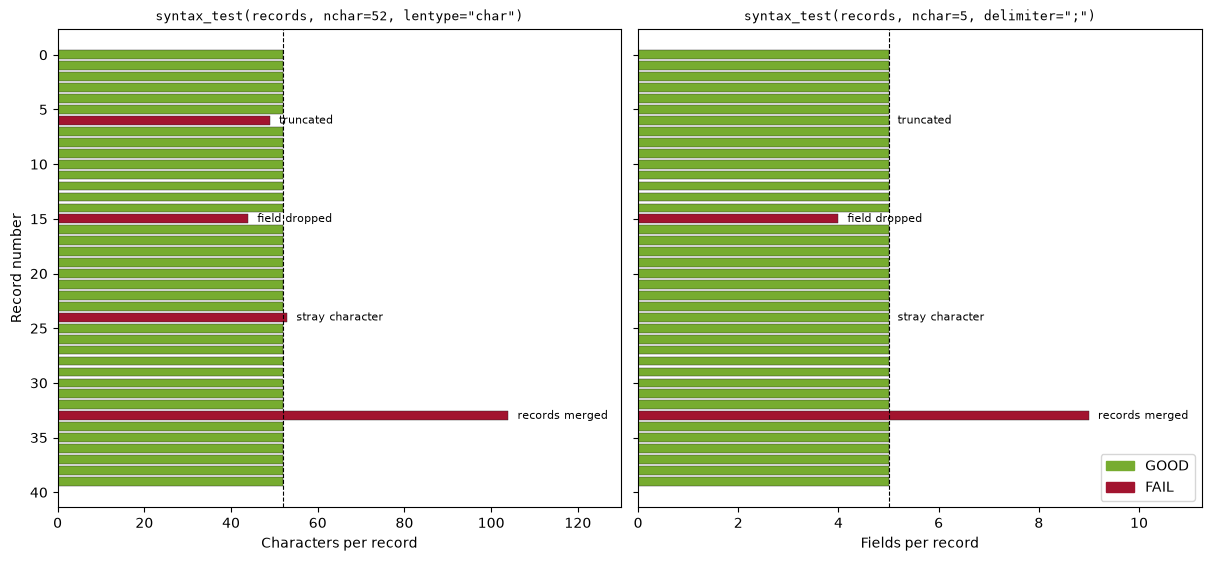

In [21]:
fig, axs = plotting_helpers.syntax_figure(records, flags_char, flags_field, good_len, good_field, damage)

## Location Test
The location test, following the 2026 GSoC, has been expanded into additional tests based on the description of intended functionalities described in the manual.
* Location test - reworked to handle basic lat/lon bounds (|lat| ≤ 90, |lon| ≤ 180) and (optionally) defined distances between points.
* Location *on land* test - flagging points that are detected to be on land, using the GSHHG coastline database for quick, high-resolution results.
* Location *bounds* test - expanding on the original `location` test by taking a user-defined coordinate shape (not just a rectangle) and then flagging either inside or outside of a range. Handy when chaining areas together, such as MPAs inside of a survey area.

### New Location Test
Similar to the `syntax` test, let's illustrate some problems that we can test by intentionally breaking the lat/lon at specific indices.
* Let's SWAP the lat/lon - this should give a huge jump both at and after the index
* There's a latitude which is 100 deg *more* than it should be
* One of the lat/lon values are missing about halfway thorough the data - this should flag the point's index as bad.
* Both values are missing at the end - this should flag 9

In [22]:
import warnings
lat_bad, lon_bad = ds.LATITUDE.copy(), ds.LONGITUDE.copy()
# i_swap, i_typo, i_half, i_none = 20000, 45000, 70000, 90000
n = ds.LATITUDE.size
i_swap, i_typo, i_half, i_none = (int(f * n) for f in (0.2, 0.45, 0.5, 0.9))
print(f"{i_swap}, {i_typo}, {i_half}, {i_none}")

lat_bad[i_swap], lon_bad[i_swap] = ds.LONGITUDE[i_swap], ds.LATITUDE[i_swap]
lat_bad[i_typo] = ds.LATITUDE[i_typo] + 100
lon_bad[i_half] = np.nan
lat_bad[i_none] = lon_bad[i_none] = np.nan

range_max = 10000   #   Meters, so 10000 = 10 km
with warnings.catch_warnings():
    #   158N isn't a valid latitude, which triggers a harmless RuntimeWarning
    warnings.simplefilter("ignore", RuntimeWarning)
    flags_loc = qartod.location_test(lon_bad, lat_bad, range_max=range_max, range_method="wgs84")

flag_counts(flags_loc, f"range_max = {range_max / 1000:.0f} km:")
for i, what in [(i_swap, "swapped"), (i_typo, "typo"), (i_half, "one missing"), (i_none, "both missing")]:
    print(f"  {what:<13s} flags (point before, point, point after): {np.ma.getdata(flags_loc)[i - 1:i + 2]}")

339816, 764586, 849541, 1529173
range_max = 10 km:          GOOD=1,699,077, MISSING=1, SUSPECT=2, FAIL=2
  swapped       flags (point before, point, point after): [1 3 3]
  typo          flags (point before, point, point after): [1 4 1]
  one missing   flags (point before, point, point after): [1 4 1]
  both missing  flags (point before, point, point after): [1 9 1]


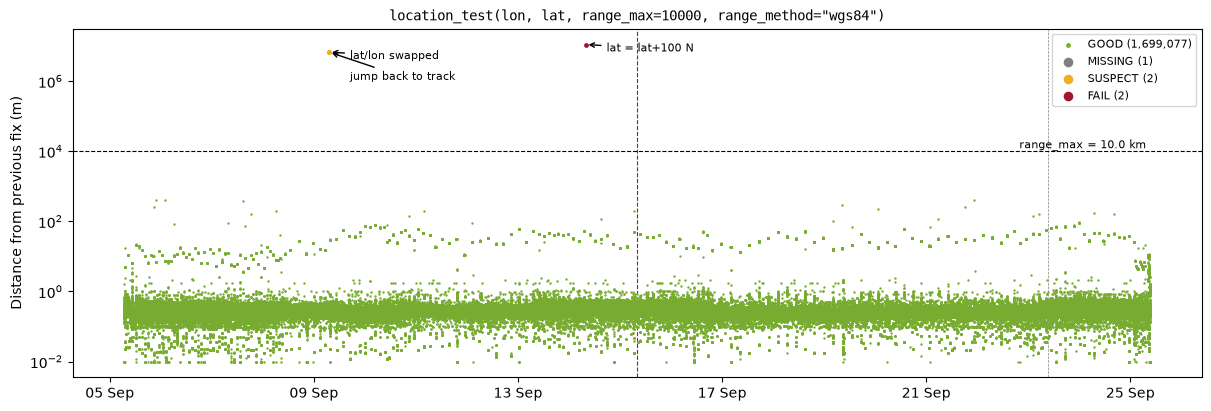

In [23]:
fig, ax = plotting_helpers.location_distance_figure(
    ds.TIME, lon_bad, lat_bad, flags_loc, range_max, i_swap, i_typo, i_half, i_none,
)

The cell above shows the distance between the points - most are within a meter apart from each other. There are actually two points at the beginning of the 9th of September because of the lat/lon swap - the calculation catches the jump back as well which is approximately the same magnitude as the initial one. The distance can't be calculated when a point is missing - so those are the vertical red and grey lines at the indices where the problem arises.

### Location on Land Test
Since our data is good, demonstrating these new tests is easiest to demonstrate by "damaging" the data again. Let's shift a few days of data north onto land.

In [24]:
import shapely
lat_shift = ds.LATITUDE.copy()
shifted = (ds.TIME > np.datetime64("2025-09-17")) & (ds.TIME < np.datetime64("2025-09-20"))
lat_shift[shifted] += 0.9

flags_land = qartod.location_on_land_test(ds.LONGITUDE, lat_shift)

If we zoom way into the Norwegian coast, we can see the high resolution afforded to us with `roaring_landmask` - especially valuable for glider operators that operate near the coast. For a comparison against `regionmask`, which uses Natural Earth, see the GSoC'26 [deliverable 2 notebook](https://github.com/Klankers/mau_gsoc_qartod/blob/main/deliverable_2.ipynb).

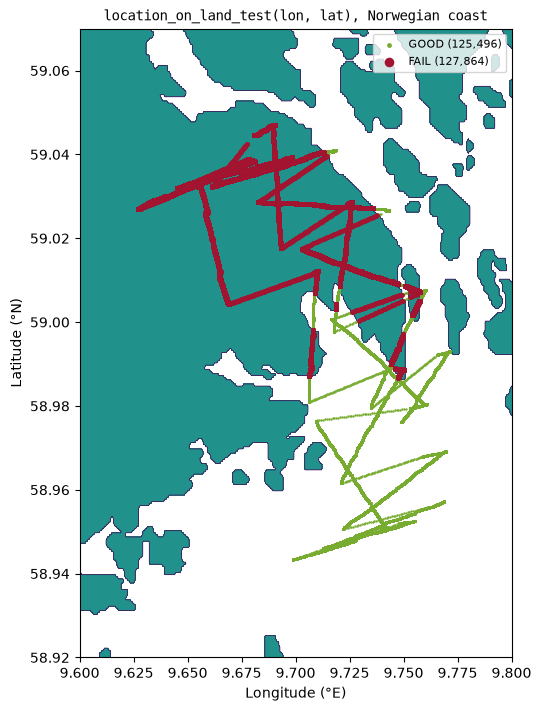

In [25]:
zoom_extent = (9.6, 9.8, 58.92, 59.07)
fig, ax = plotting_helpers.land_zoom_figure(
    ds.LONGITUDE[shifted], lat_shift[shifted], flags_land[shifted], zoom_extent,
    title="location_on_land_test(lon, lat), Norwegian coast",
)

### Location bounds
And now to show what this data looks like with the `location bounds test` in place. Say we want to define a working area that we're not expecting the glider to leave (`operating_area`), as well as another area that the glider should *not* be working in, like a shipping lane or MPA (`exclusion_zone`).

On our newly shifted data, we should see that there are flags that are inside and outside of the two bounded areas we've designated. QARTOD has a flag aggregator, `qartod_compare`, which can be used to summarize all these flags in the end (`flags_bounds`).

In [26]:
#   Setting up for a survey area, with an exclusion zone inside to demonstrate chaining
operating_area = shapely.Polygon([(9.45, 57.92), (11.0, 57.92), (11.0, 58.28), (9.45, 58.28)])
exclusion_zone = shapely.Polygon([(10.15, 58.0), (10.35, 58.0), (10.35, 58.2), (10.15, 58.2)])
flags_outside = qartod.location_bounds_test(ds.LONGITUDE, lat_shift, shape=operating_area, flag_area="outside")
flags_inside = qartod.location_bounds_test(ds.LONGITUDE, lat_shift, shape=exclusion_zone, flag_area="inside")
flags_bounds = qartod.qartod_compare([flags_outside, flags_inside])

flag_counts(flags_land, "On land:")
flag_counts(flags_outside, "Outside operating area:")
flag_counts(flags_inside, "Inside exclusion zone:")
flag_counts(flags_bounds, "Bounds, combined:")

On land:                    GOOD=1,571,218, FAIL=127,864
Outside operating area:     GOOD=1,445,722, FAIL=253,360
Inside exclusion zone:      GOOD=1,683,551, FAIL=15,531
Bounds, combined:           GOOD=1,430,191, FAIL=268,891


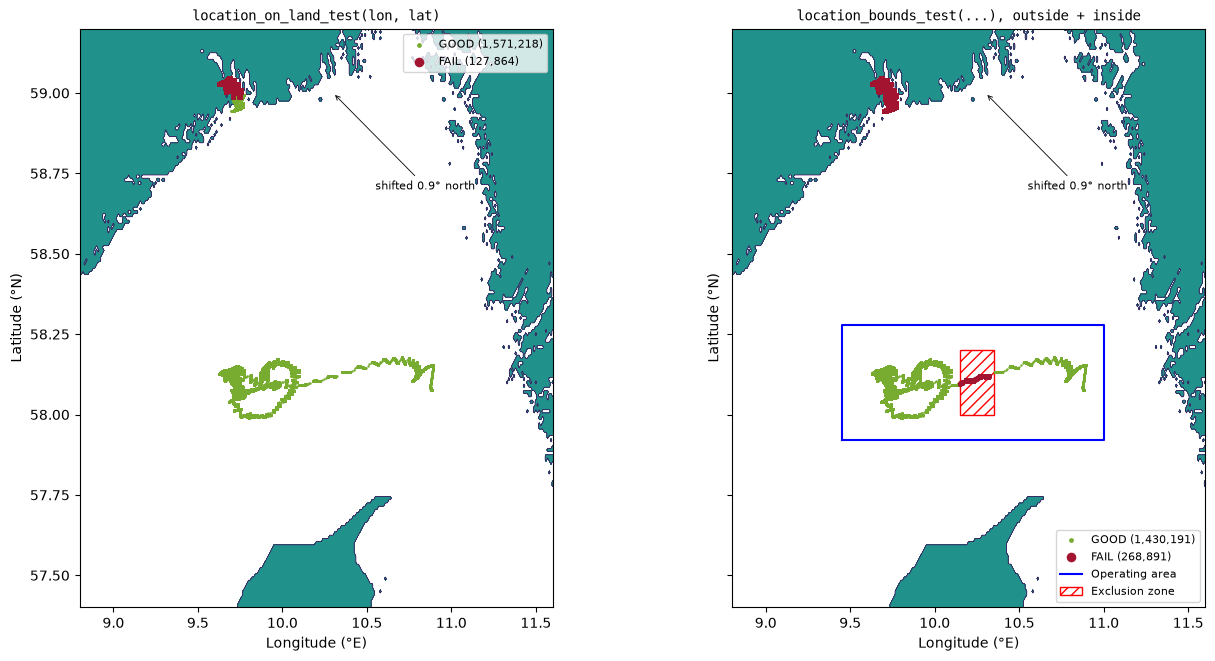

In [27]:
fig, axs = plotting_helpers.land_and_bounds_figure(
    ds.LONGITUDE, lat_shift, flags_land, flags_bounds, extent, operating_area, exclusion_zone,
)

Without the study area, we see the same results as before. Some of the poitns are on land. With the study area defined, *all* of the points near the coast fail, because they're outside the defined shape. Within the study area, however, there is also a subdomain which we're flagging inside of. So there is a second range of flags that has been applied.

## Gross Range Test
The `gross_range_test` is perhaps the most important test that is also the easiest to understand. Flag values that aren't within a specific range, with some optional tolerance between being a suspicious value and a bad value.

This has been expanded into the percentile range test (discussed later), for working with variables where maybe the bounds aren't known.

In [28]:
for var in ["TEMP", "CHLA"]:
    attrs = ds[var].attrs
    print(f"{var}: valid range {attrs['valid_min']} to {attrs['valid_max']} {attrs['units']}")

TEMP: valid range -5.0 to 42.0 Degrees Celsius
CHLA: valid range 0.0 to 50.0 mg m-3


A handy attribute present in the OG1 format is the `valid_min` and `valid_max`, which is something that echoes manufacturer or institutional specifications. These can be a good start in some cases without doing the percentile range test.

This data is from the Skagerrak, which typically doesn't get as warm or salty as a gyre. We can initialize our `fail_span` with the valid ranges, and then further constrain to about 7-22 °C.

In [29]:
temp_fail = (float(ds.TEMP.attrs["valid_min"]), float(ds.TEMP.attrs["valid_max"]))
temp_suspect = (7, 22)
flags_temp = qartod.gross_range_test(temp, fail_span=temp_fail, suspect_span=temp_suspect)
flag_counts(flags_temp, "TEMP:")

TEMP:                       GOOD=1,698,837, MISSING=237, SUSPECT=8


In [30]:
print(np.where(flags_temp == 3))

(array([1694431, 1694432, 1694433, 1694434, 1694435, 1694436, 1694437,
       1694438]),)


Looks like there aren't too many bad flags here - they're all at the end.

Let's visualize these ranges in a couple of different ways. First - the most intuitive way, looking at where the value itself steps into each one as a function of time. Second, as a histogram to show how often the bound is being violated. Showing the distribution from a depth perspective is also helpful - given many sensors can have problems at the surface. It's nice to know *where* the issue is happening.

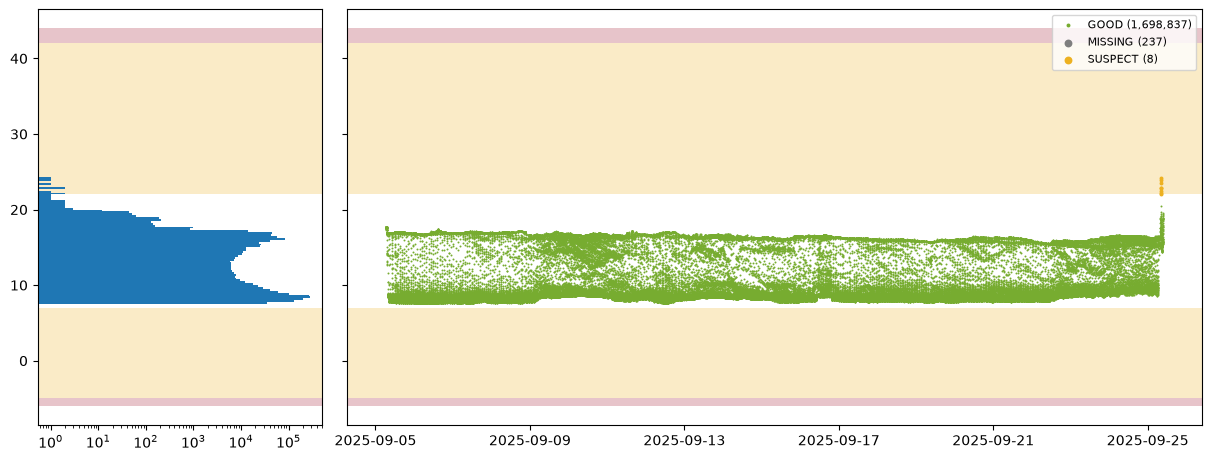

In [31]:
fig, axs = plotting_helpers.gross_range_figure_val(
    time, temp, flags_temp, temp_fail, temp_suspect,
    bins=np.linspace(-6, 44, 201),
)

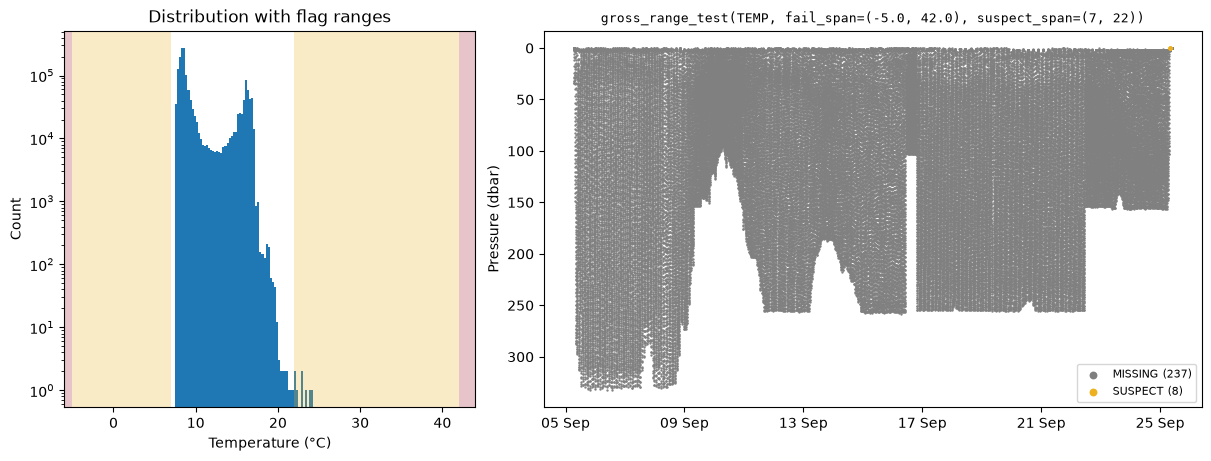

In [32]:
fig, axs = plotting_helpers.gross_range_figure_pres(
    time, pres, temp, flags_temp, temp_fail, temp_suspect, "Temperature (°C)",
    f"gross_range_test(TEMP, fail_span={temp_fail}, suspect_span={temp_suspect})",
    bins=np.linspace(-6, 44, 201),
)

So we can see that the 8 suspect values are at the very end, when the glider is being recovered or is at the surface. This will likely be different for an optical sensor, which is more likely to get spikes.

Note: There's a chlorophyll value of ±500 in here - cutting down to a smaller window using `np.clip` helps make things more legible.

In [33]:
chla = ds.CHLA.values
chla_fail = (float(ds.CHLA.attrs["valid_min"]), float(ds.CHLA.attrs["valid_max"]))
chla_suspect = (0, 10)
flags_chla = qartod.gross_range_test(chla, fail_span=chla_fail, suspect_span=chla_suspect)
print(f"Fail: {chla_fail}, Sus: {chla_suspect}")
print(f"{np.nanmin(chla)}-{np.nanmax(chla)}")
flag_counts(flags_chla, "CHLA:")
print(f"Of which pinned at +/-500: {np.count_nonzero(np.abs(chla) == 500)}")

Fail: (0.0, 50.0), Sus: (0, 10)
-500.0-500.0
CHLA:                       GOOD=1,690,361, MISSING=585, SUSPECT=676, FAIL=7,460
Of which pinned at +/-500: 35


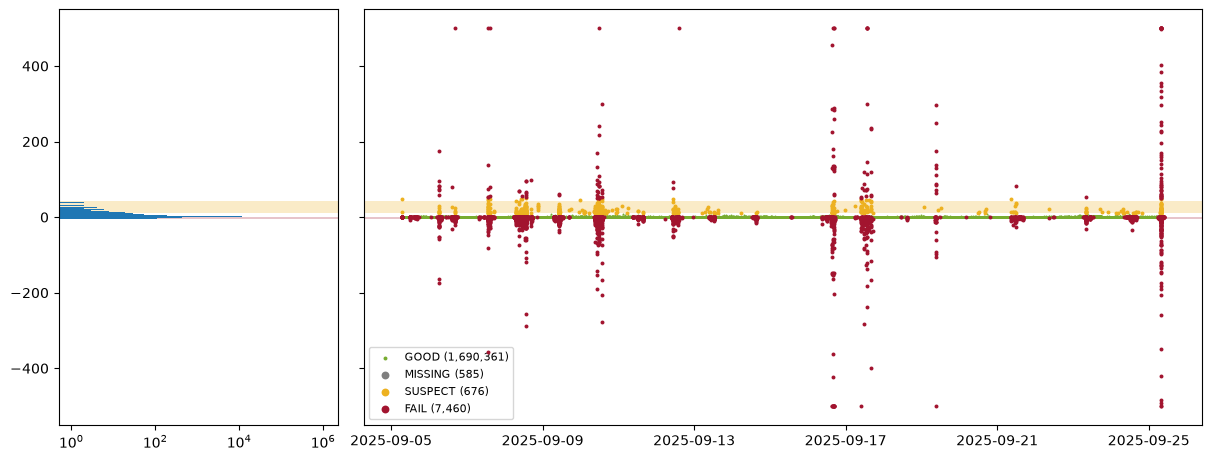

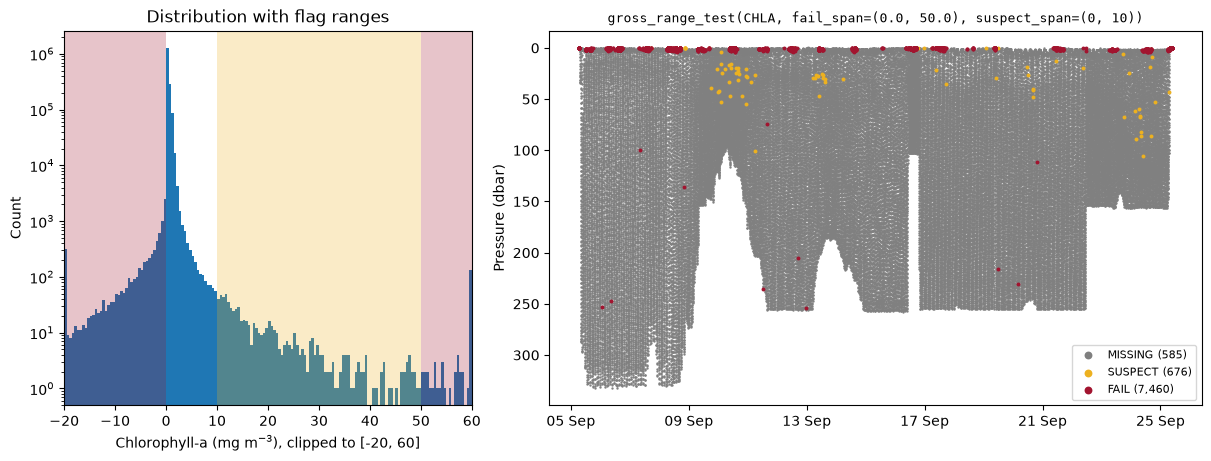

In [34]:
fig, axs = plotting_helpers.gross_range_figure_val(
    time, chla, flags_chla, chla_fail, chla_suspect,
    bins=np.linspace(-6, 44, 201),
)
fig, axs = plotting_helpers.gross_range_figure_pres(
    time, pres, np.clip(chla, -20, 60), flags_chla, chla_fail, chla_suspect,
    "Chlorophyll-a (mg m$^{-3}$), clipped to [-20, 60]",
    f"gross_range_test(CHLA, fail_span={chla_fail}, suspect_span={chla_suspect})",
    bins=np.linspace(-20, 60, 161),
)

So in this case, we can see that there are lots of recurring issues with chlorophyll that are happening at the surface, but the ocassional issues are happening at depth - possibly optical spikes that could be ignored, given they don't have obvious trends from a depth perspective.

## Percentile Range Test
The `percentile_range_test` grew from the `gross_range_test`, mostly as a way of avoiding a fixed spans and being bounded by the data itself. The user can define `low` and `hi_percentiles` for the data, widened by an optional `pad` argument, which will define the flagging. These default to the 5th and 95th percentiles with a `pad` of 0.

It's worth noting that this `pad` is in whatever unit the variable is. So for example, if one were to do flagging from the 1st and 99th percentiles for temperature, you could add a 1 °C padding to this to reduce the amount of flagging that is done by values that could be totally statistically fine (otherwise, you're guaranteed to flag 2% of the data).

Because of the statistical nature of this test, there are no `fail` flags assigned as there are for the `gross_range_test`.

In [35]:
pct_runs = {
    "defaults (5th-95th)": {},
    "1st-99th, pad = 1 °C": {"low_percentile": 1, "hi_percentile": 99, "pad": 1},
}
pct_flags = {name: qartod.percentile_range_test(temp, **kw) for name, kw in pct_runs.items()}
for name, flags in pct_flags.items():
    flag_counts(flags, name)

defaults (5th-95th)         GOOD=1,528,995, MISSING=237, SUSPECT=169,850
1st-99th, pad = 1 °C        GOOD=1,697,989, MISSING=237, SUSPECT=856


By loosening the statistical restrictions and adding a padding value, the number of suspect points has dropped signicantly. The `pad` value is why the value is less than 2% of the total data size.

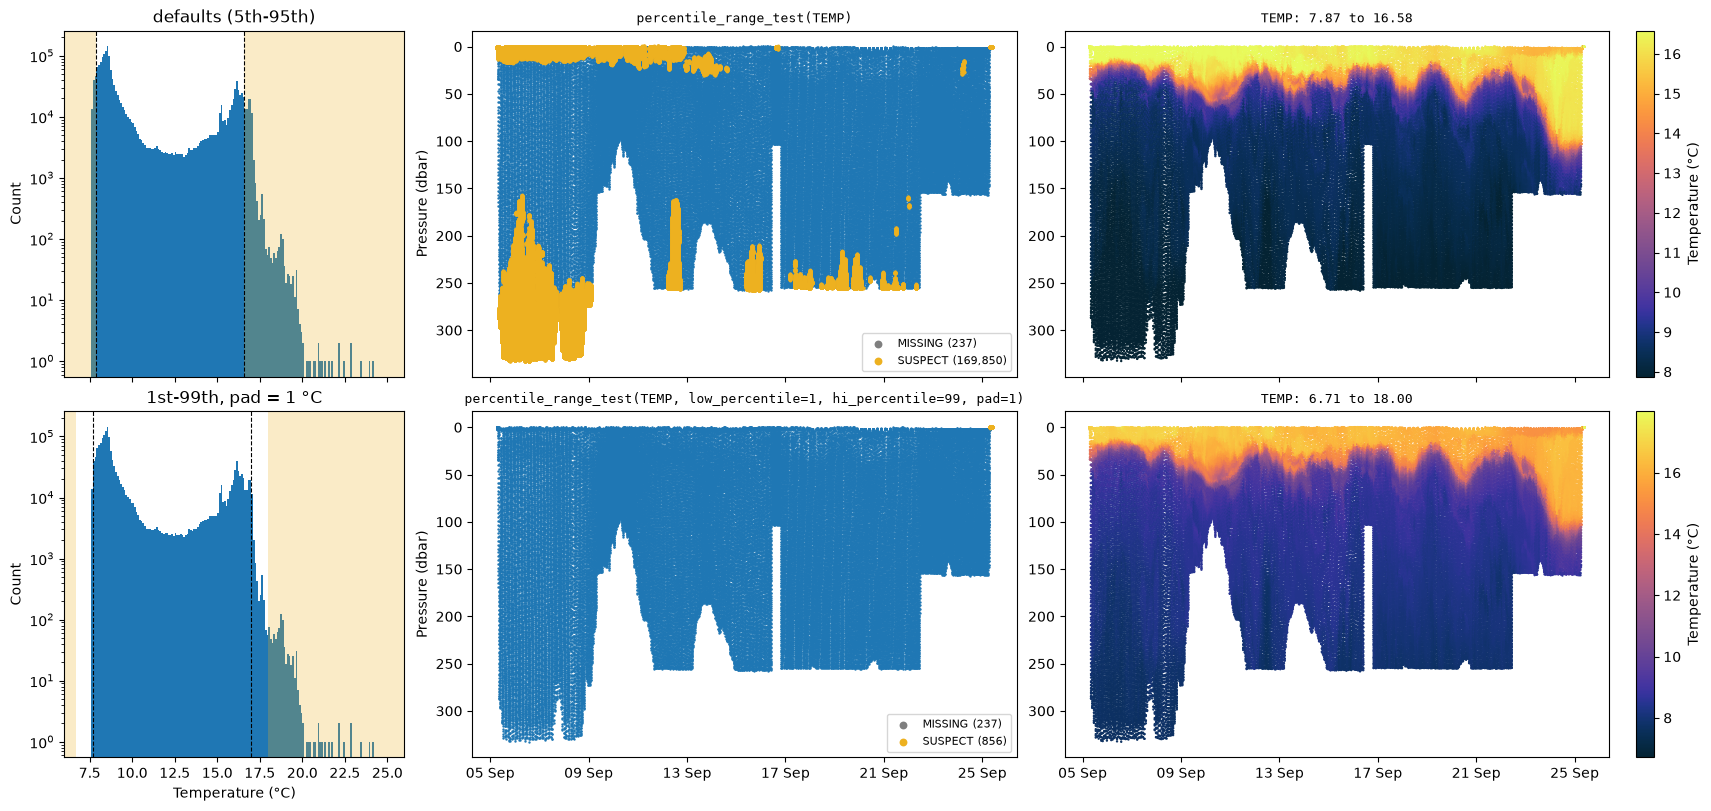

In [36]:
fig, axs = plotting_helpers.percentile_range_figure(time, pres, temp, pct_runs, pct_flags, bins=np.linspace(6, 26, 201))

As you can see, the defaults are flagging about 10% of the data, mostly because the values early and deep are *too cold*, as indicated in the more intense colorbar limits in the last column. This is loosened slightly with the 1-99 percentile and by introducing a padded value.
* Increasing the percentile tolerance - shifted the vertical dotted boundaries outwards in the first column and loosened the colorbar in the final column.
* Increasing the padding provided a buffer zone between the percentile tolerance and where the suspect values began.

This new range is about 6-17.9 °C, which is similar to what we assigned for the suspect range in the `gross_range_test`.

However, we can still see that the points at the very end (near the recovery or at the surface) is where temperature is being flagged even with our tolerance changes. That's good - it informs the user that they're approaching something without necessarily knowing what it should be.

## Climatology Test
The climatology test is similar to the `gross_range_test` in that it's like pairing a series of them together based on particular spatiotemporal domains. This uses a time span (`tspan`), and an optional depth span (`zspan`) for flagging specific sections of the data.

Historically, it has been implemented by a `ClimatologyConfig` object, then manually adding each config. During the 2026 Google Summer of Code, this was simplified to handle a list of dictionaries. In this section, we'll walk through it both ways. Both the legacy option (`ClimatologyConfig`), and the latest version as a series of dictionaries.

We'll start by building a series of depth slizes with `zspan` and different temperature tolerances, `vspan`, for a fixed time period (let's say a month). Just throwing out some rough estimates of the Skagerrak, the mixed layer can be vary but we can start with a 30 m depth guess.

Depth is using meters, so we'll want to convert from pressure using `gsw`.

In [37]:
depth = -gsw.z_from_p(pres, ds.LATITUDE.values)

clim = qartod.ClimatologyConfig()
clim.add(tspan=("2025-09-01", "2025-10-01"), zspan=(0, 30), vspan=(10, 20))
clim.add(tspan=("2025-09-01", "2025-10-01"), zspan=(30, 400), vspan=(7, 16))
flags_clim = qartod.climatology_test(clim, temp, time, depth)
flag_counts(flags_clim, "Climatology:")

Climatology:                UNKNOWN=2,346, GOOD=1,659,931, MISSING=237, SUSPECT=36,568


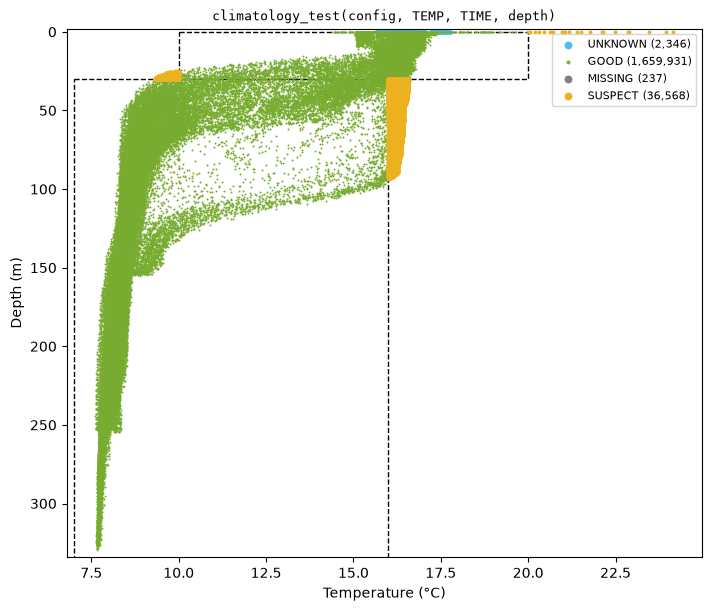

In [38]:
fig, ax = plotting_helpers.climatology_figure(
    temp, depth, flags_clim, boxes=[((0, 30), (10, 20)), ((30, 400), (7, 16))],
)

So we can see that we've got bounding conditions that might be too lenient at the surface, and too strict at depth, depending on when most of these high temperature values at 100 m are showing up.

It's also worth noting that the climatology is a test that only runs on the subsection of the data that we've specified. There are still about 2,300 points that aren't assessed by this - since these spatioemporal periods have not been defined.

Moving on to an example of passing in dictionaries directly to the `climatology_config` parser, which checks the `period` and individual spans. Let's designate an additional span that defines the `fail` span.

In [39]:
clim_windows = qartod.climatology_config([
    {"tspan": ("2025-09-01", "2025-10-01"), "vspan": (6, 22), "zspan": (-5, 400)},  # catch-all, applied first
    {"tspan": (9, 9), "period": "month", "vspan": (10, 20), "fspan": (5, 22), "zspan": (0, 30)},
    {"tspan": (9, 9), "period": "month", "vspan": (7, 16), "zspan": (30, 400)},
])

for window in clim_windows:
    print(window)

flags_clim_windows = qartod.climatology_test(clim_windows, temp, time, depth)
flag_counts(flags_clim_windows, "Climatology (windows):")

{'tspan': Span(minv=Timestamp('2025-09-01 00:00:00'), maxv=Timestamp('2025-10-01 00:00:00')), 'vspan': Span(minv=6, maxv=22), 'fspan': None, 'zspan': Span(minv=-5, maxv=400), 'period': None}
{'tspan': Span(minv=9, maxv=9), 'vspan': Span(minv=10, maxv=20), 'fspan': Span(minv=5, maxv=22), 'zspan': Span(minv=0, maxv=30), 'period': 'month'}
{'tspan': Span(minv=9, maxv=9), 'vspan': Span(minv=7, maxv=16), 'fspan': None, 'zspan': Span(minv=30, maxv=400), 'period': 'month'}
Climatology (windows):      GOOD=1,662,277, MISSING=237, SUSPECT=36,560, FAIL=8


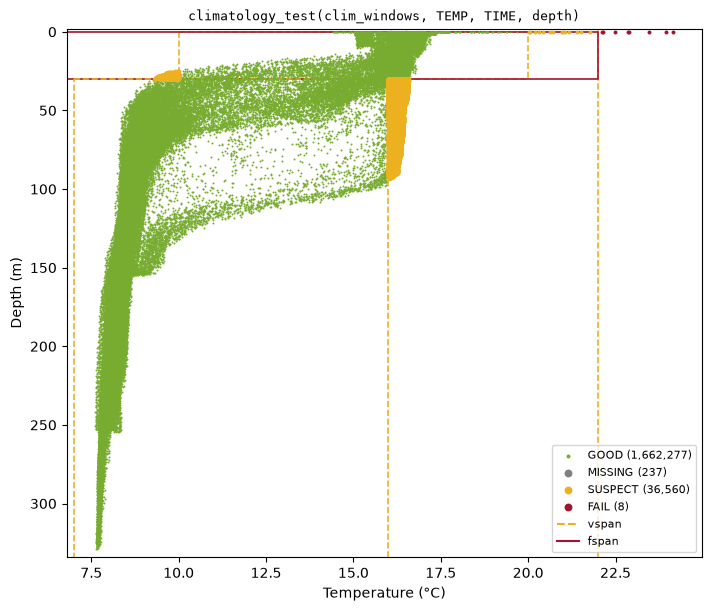

In [40]:
fig, ax = plotting_helpers.climatology_windows_figure(temp, depth, flags_clim_windows, clim_windows)

So the `fspan` window has expanded the range in the mixed layer for that period.

## Pressure Test
The pressure test works to look for a monotonic sequence during the down and upcasts of a glider. By differentiating the pressure, one can mark points as suspect if they don't move up or down by a specified amount in a given direction (`direction` is up or down, `pad` by X dbar).

Furthermore, gliders can have issues during down or upcasts where they struggle to punch through a layer. If `assess_floating` is turned on, the test starts looking at the points immediately after one that has been flagged for not going up/down by `pad` dbar and flags all the next points. If the glider doesn't hit the specified change in depth defined by the `breakout` (dbar) value, then the point is flagged.

Because it requires a direction, this test is best when assigned to an individual profile. For a more automatic version of this test (albeit, without the glider manual's description of floating gliders being flagged), see `argo.pressure_increasing_test`.

So we'll slice up our data by profile number and then pass that into our test.

In [41]:
starts = np.r_[0, np.flatnonzero(np.diff(profile)) + 1]
profile_slices = [
    slice(a, b) for a, b in zip(starts, np.r_[starts[1:], profile.size],
    strict=True)
]

#   We'll want a loop that goes through, assigning "down" or "up" based on the profile number.
def pressure_test_by_profile(pres, **kwargs):
    flags = np.full(pres.size, QartodFlags.UNKNOWN, dtype="uint8")
    for s in profile_slices:
        updown = "down" if direction[s.start] == 1 else "up"
        flags[s] = qartod.pressure_test(pres[s], updown, **kwargs)
    return flags

flags_pres = pressure_test_by_profile(pres, pad=0.01)
flags_pres_float = pressure_test_by_profile(pres, pad=0.01, assess_floating=True, breakout=0.025)
flag_counts(flags_pres, "pad=0.01:")
flag_counts(flags_pres_float, "+ assess_floating:")

pad=0.01:                   GOOD=1,620,881, MISSING=237, SUSPECT=77,964
+ assess_floating:          GOOD=1,608,308, MISSING=237, SUSPECT=90,537


As you can see above, adding the `assess_floating` parameter increases the number of suspect points by about 13,000 points. This is most evident if we plot both a downcast and an upcast next to each other. Common areas where this happens is at the bottom of a cast, when it's inflecting up, and at the end of a cast at the surface communicating with the satellite. I found a good example at casts 115 and 116, but this behavior can be seen elsewhere. If you adjust the `down` cycle to 117, you'll note how there is no transmission period present, as the glider will do multiple dives before transmitting again.

We'll zoom into the transmission period for the profile to more easily show the oscillations while transmitting prior to going up for another dive.

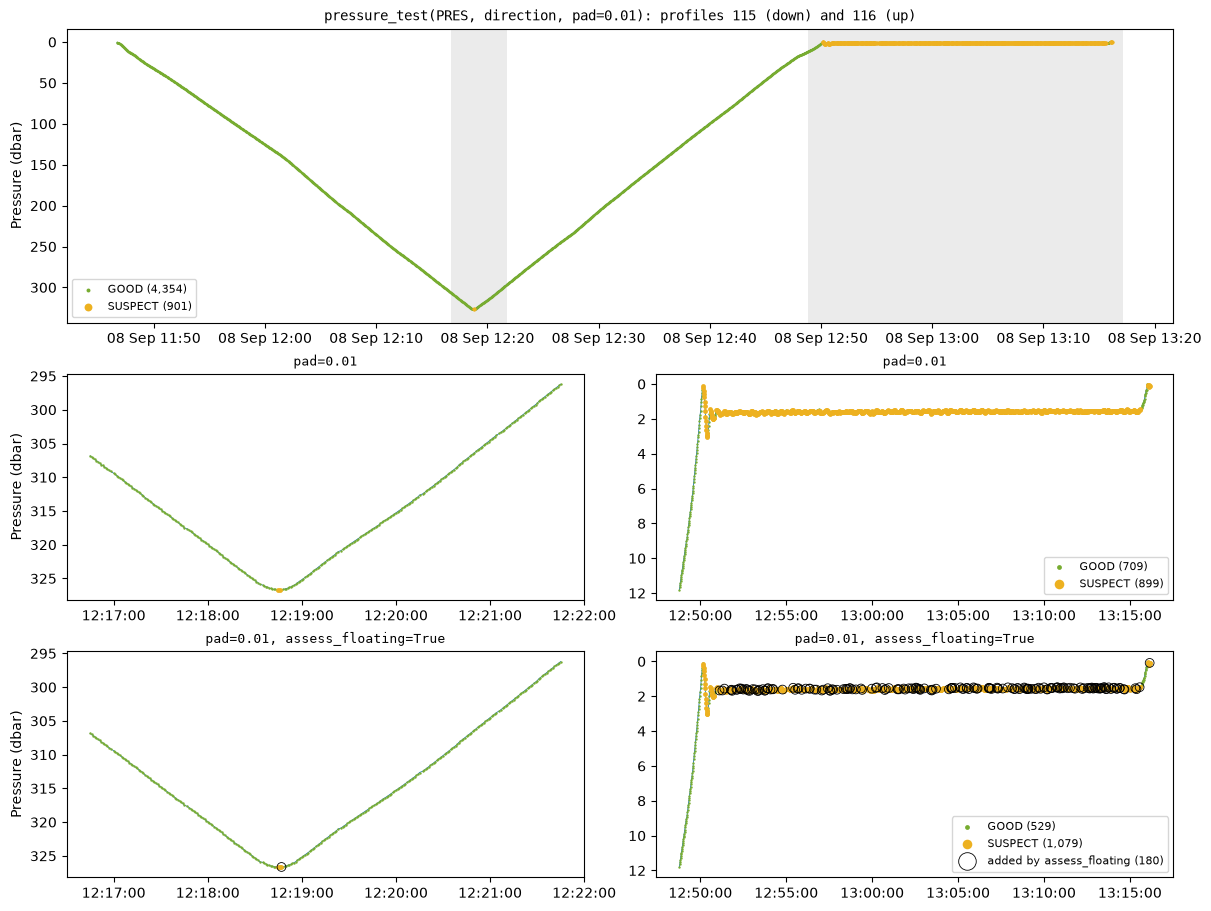

In [42]:
down = 115  #   Should be odd, the upcast that follows is plotted with it
fig, axs = plotting_helpers.pressure_cycle_figure(time, pres, profile, flags_pres, flags_pres_float, down)

Note how there are additional poitns added by the `assess_floating` designation, both at the inflection and at the surface. This could be made stricter by increasing the `breakout` requirement for the diff of the pressure.

For a better sense of this, we can look at how much of the upcast and downcast is flagged. Given we've already seen the geographic plots earlier, we know that the glider piloting behavior early in the mission was likely related to wrestling to stay on station (making that wide loop), where the glider was probably communicating more at the surface. This transitioned more into the downcast later in the mission. It's periodic - which makes sense given the glider may accomplish multiple profiles prior to transmitting with the surface.

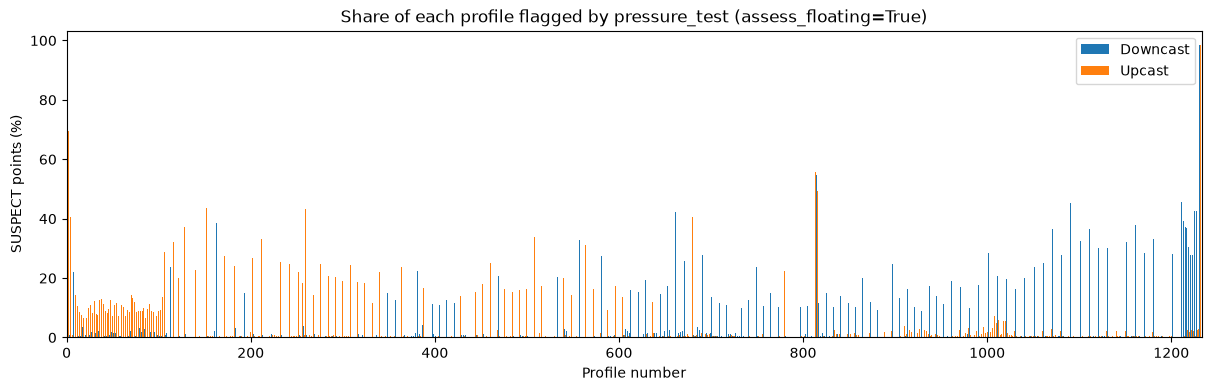

In [43]:
fig, ax = plotting_helpers.suspect_share_figure(flags_pres_float, profile_slices, profile, direction)

Given this, there are some other profiles that can be inspected. Here are some more examples that can be inspected by rerunning the earlier cell in this section:
* Transmission at the end of the upcast (orange) - 101, 115, 779
* Transmission at the beginning of the downcast (blue) - 413, 1111

## Density Inversion Test
In 99% of cases, seawater density increases with depth. The `density_inversion_test` looks for inversions - where the general rule of "density *decreases* as depth *increases*", or where the depth derivative of density is positive, is not true. Whenever this inverses (or the derivative goes negative), *or* falls below an optional threshold, both of the points are flagged.

Similar to the `gross_range_test`, this density derivative threshold accomodates for suspect and fail flags. With `ds["SIGMA0"]` or `sigma0` defined by `gsw`, we can look at what different threwsholds would potentially flag. In the docstring, 0.03 and 0.01 were suggested for suspect and fail thresholds, respectively, but it's worth looking at more. There is no reason the thresholds can't be negative - especially if changes in density are very small or data are noisy.

In [44]:
delta = np.sign(np.diff(pres)) * np.diff(sigma0)
for threshold in [0.03, 0.01, 0, -0.01, -0.03, -0.1]:
    print(f"delta < {threshold:>5}: {np.nanmean(delta < threshold) * 100:2f}% of point pairs")

delta <  0.03: 94.661820% of point pairs
delta <  0.01: 85.358556% of point pairs
delta <     0: 42.484496% of point pairs
delta < -0.01: 7.717525% of point pairs
delta < -0.03: 2.249804% of point pairs
delta <  -0.1: 0.106587% of point pairs


For this data, the depth and density is spaced differently than in the example. So the $\delta_\sigma$ or the $\delta_{depth}$ could be leading to smaller expected changes in density. Though it is concerning to see a value of 0 shows 42% of the data being flagged. Why is that?

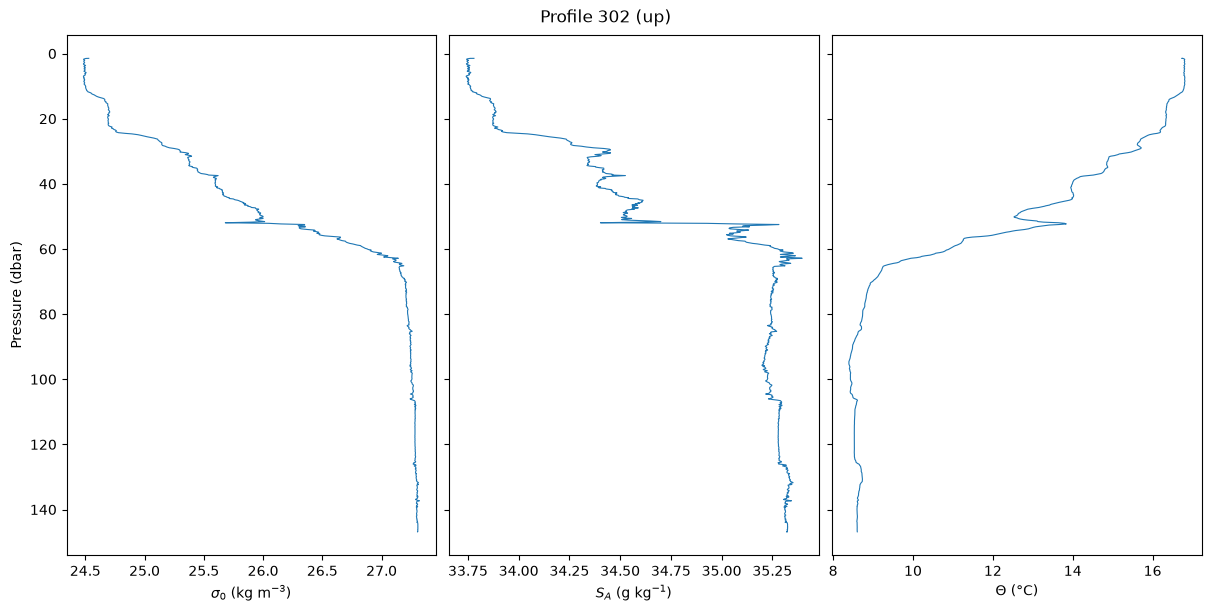

In [45]:
fig, axs = plotting_helpers.profile_panels_figure(
    pres, profile, 302,
    panels=[
        (sigma0, r"$\sigma_0$ (kg m$^{-3}$)"),
        (ds["SA"].values, r"$S_A$ (g kg$^{-1}$)"),
        (ds["CT"].values, r"$\Theta$ (°C)"),
    ],
    title="Profile 302 (up)",
)

That explains it - there are lots of micro-turbulent exceptions that may be coming from T and S used in the derivation of $\sigma_0$. This explains why so much of the data is being flagged - any kind of wobble pushes a data point *pair* into the flagged category.

Because we aren't filtering this data, we'll pass through some lenient bounds. We can see a clear spike around 55 m on this upcast, so let's assign a tolerance around -0.1 to flag that as definitely bad and a suspect value that will be between 0 and -0.1 to handle the noise that is being introduced by our $S_A$, used to derive $\sigma_0$.

In [46]:
di_suspect, di_fail = -0.05, -0.1

flags_dens = np.full(pres.size, QartodFlags.UNKNOWN, dtype="uint8")
for s in profile_slices:
    flags_dens[s] = qartod.density_inversion_test(sigma0[s], pres[s], suspect_threshold=di_suspect, fail_threshold=di_fail)
flag_counts(flags_dens, "Density inversion:")

Density inversion:          GOOD=1,665,067, MISSING=6,738, SUSPECT=23,802, FAIL=3,475


Less than 1% of the points are being flagged with these tolerances, so we're not getting all the undulations inherent to noise in the derived variables.

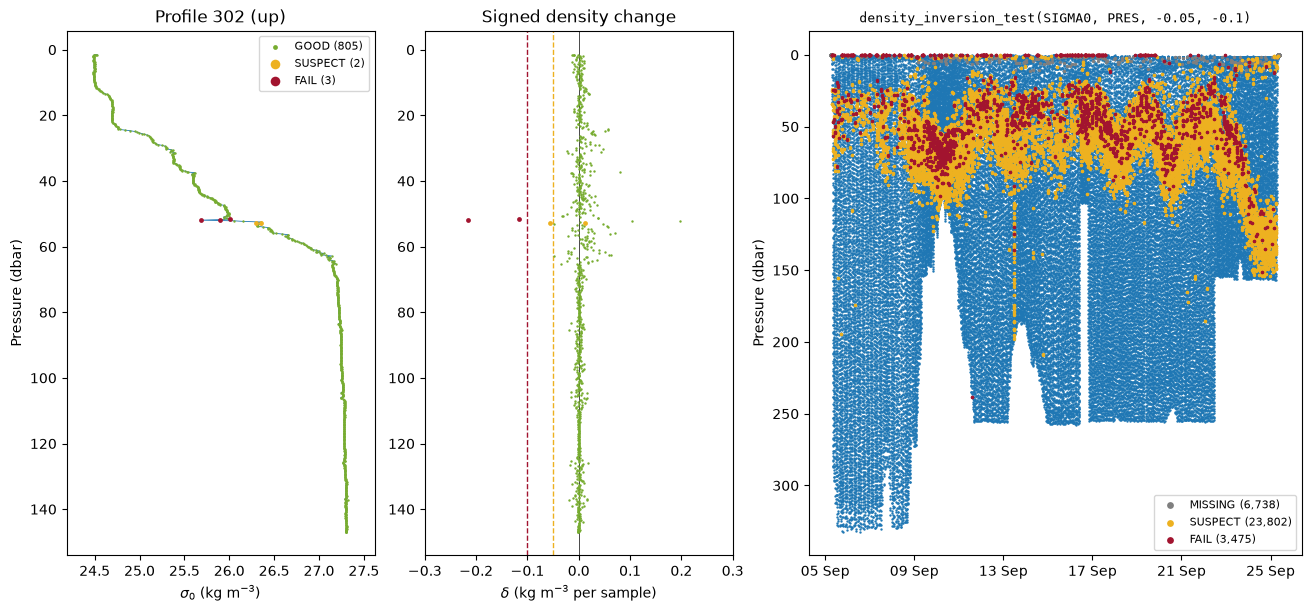

In [47]:
fig, axs = plotting_helpers.density_inversion_figure(
    time, pres, sigma0, profile, direction, profile_slices, flags_dens, 302, di_suspect, di_fail,
)

As per these results, we can see that profile 302 has three fail flags. This is because there are actually two points that go into this inversion.

In [48]:
sigma0[profile == 302][515:525]

array([26.15142867, 26.04840159, 25.68133185, 25.89739762, 26.01321673,
       25.97657509, 25.93898637, 25.93684864, 25.96887979, 26.00028115])

This is on the upcast, so we are expecting the density to *decrease*. When it goes from 25.68 to 25.89, and then to 26.01, all three points are flagged since they exceed the change of 0.1 we've assigned the test. This is reflected in the middle plot - these points lie outside of our defined tolerance for density inversion and are flagged as failing the test. There are two points flagged as suspect, and because we don't know which one is good, even the point with a positive value is flagged in yellow.

Looking at the final column, which takes all the profiles into account, we can see that this dataset is failing the test pretty consisitently with respect to other profiles. It's possible that the glider wasn't handling the salinity gradient well, or that the data should be filtered before running the test to remove some spikes and noise.